# Proyect Plan

data -> Generated with Python

arquitecture -> 

activation function

loss function

optimizer

# Data Generator

In [1]:
import numpy as np

rows_num = 100_000
rng = np.random.default_rng()

inputs = rng.integers(-10, 11, size=(rows_num, 2), dtype=np.int32)
targets = inputs.sum(axis=1, dtype=np.int32)

data = np.column_stack((inputs, targets))

print(data.shape)  # (100000, 3)
print(data[:5])

(100000, 3)
[[10  6 16]
 [ 9 -3  6]
 [ 8 -9 -1]
 [ 7  8 15]
 [ 4  7 11]]


In [2]:
data

array([[ 10,   6,  16],
       [  9,  -3,   6],
       [  8,  -9,  -1],
       ...,
       [-10,   7,  -3],
       [ -5,  -1,  -6],
       [ 10,  -9,   1]], shape=(100000, 3), dtype=int32)

# Manage Data

In [3]:
# Normalize Data
X = data[:,:2].astype(np.float32) / 10.0
y = data[:,2].astype(np.float32) / 20.0


# Split Data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [4]:
import torch

# numpy to tensor
X_train = torch.from_numpy(X_train)
X_test = torch.from_numpy(X_test)
y_train = torch.from_numpy(y_train)
y_test = torch.from_numpy(y_test)

# TensorDataset and DataLoader 
from torch.utils.data import DataLoader, TensorDataset

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=True, drop_last=True)

# CUDA

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Entrenando en: {device}")

Entrenando en: cuda


# ANN Arquitecture

In [6]:
import torch.nn as nn

class AddingMachine(torch.nn.Module):
    def __init__(self):
        super().__init__()
        
        # input 
        self.input = nn.Linear(2, 16)
        
        # hidden 
        self.fc1 = nn.Linear(16,32)
        self.fc2 = nn.Linear(32,16)
        
        # activation 
        self.relu = nn.ReLU()
        
        # output
        self.output = nn.Linear(16,1)
    
    def forward(self, x):
        x = self.relu( self.input(x) )
        x = self.relu( self.fc1(x) )
        x = self.relu( self.fc2(x) )
        return self.output(x) 

net = AddingMachine()

lossfun = nn.MSELoss()

optimizer = torch.optim.Adam(net.parameters(), lr=0.01)

# Training

In [7]:
import time

In [8]:
import time

def trainModel():
    timer = time.process_time()

    numepochs = 10

    losses = torch.zeros(numepochs)
    trainMAE = []
    testMAE = []
    testMSE = []

    # === Train ===
    for epochi in range(numepochs):

        net.train()

        batchLoss = []
        batchMAE = []

        for X, y in train_loader:

            # Forward
            yHat = net(X).squeeze(-1)
            loss = lossfun(yHat, y)

            # Backward
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Metrics
            batchLoss.append(loss.item())
            batchMAE.append(torch.abs(yHat - y).mean().item())

        # Store epoch metrics
        losses[epochi] = torch.tensor(batchLoss).mean()
        trainMAE.append(torch.tensor(batchMAE).mean().item())


        # === Test ===
        net.eval()

        batchMAE = []
        batchMSE = []

        with torch.no_grad():

            for X, y in test_loader:

                yHat = net(X).squeeze(-1)

                batchMAE.append(
                    torch.abs(yHat - y).mean().item()
                )

                batchMSE.append(
                    torch.mean((yHat - y) ** 2).item()
                )

        testMAE.append(torch.tensor(batchMAE).mean().item())
        testMSE.append(torch.tensor(batchMSE).mean().item())

        # Iteration info
        run_time = time.process_time() - timer

        print(
            f"Epoch {epochi+1}/{numepochs} | "
            f"Train Loss: {losses[epochi]:.6f} | "
            f"Train MAE: {trainMAE[epochi]:.6f} | "
            f"Test MAE: {testMAE[epochi]:.6f} | "
            f"Test MSE: {testMSE[epochi]:.6f} | "
            f"Time: {run_time:.2f}s"
        )
    
    mae_mean = np.mean(testMAE)
    print(f"Mean Test MAE: {mae_mean:.6f}")
    mse_mean = np.mean(testMSE)
    print(f"Mean Test MSE: {mse_mean:.6f}")
    
    return losses, trainMAE, testMAE, testMSE, run_time


In [9]:
models_performance = []

for i in range(5):
    print(f"- Training model {i + 1}/3 -")

    losses, trainMAE, testMAE, testMSE, run_time = trainModel()

    models_performance.append(
        (losses, trainMAE, testMAE, testMSE, run_time)
    )

- Training model 1/3 -
Epoch 1/10 | Train Loss: 0.000497 | Train MAE: 0.005591 | Test MAE: 0.002114 | Test MSE: 0.000012 | Time: 12.95s
Epoch 2/10 | Train Loss: 0.000055 | Train MAE: 0.003638 | Test MAE: 0.000598 | Test MSE: 0.000001 | Time: 25.91s
Epoch 3/10 | Train Loss: 0.000036 | Train MAE: 0.002764 | Test MAE: 0.000574 | Test MSE: 0.000001 | Time: 38.73s
Epoch 4/10 | Train Loss: 0.000025 | Train MAE: 0.001970 | Test MAE: 0.000434 | Test MSE: 0.000000 | Time: 52.28s
Epoch 5/10 | Train Loss: 0.000029 | Train MAE: 0.002783 | Test MAE: 0.002445 | Test MSE: 0.000007 | Time: 67.20s
Epoch 6/10 | Train Loss: 0.000012 | Train MAE: 0.001059 | Test MAE: 0.004062 | Test MSE: 0.000027 | Time: 78.93s
Epoch 7/10 | Train Loss: 0.000021 | Train MAE: 0.001503 | Test MAE: 0.000813 | Test MSE: 0.000001 | Time: 93.76s
Epoch 8/10 | Train Loss: 0.000019 | Train MAE: 0.001556 | Test MAE: 0.000658 | Test MSE: 0.000001 | Time: 106.15s
Epoch 9/10 | Train Loss: 0.000012 | Train MAE: 0.001106 | Test MAE: 0.00

# Analyze Performance

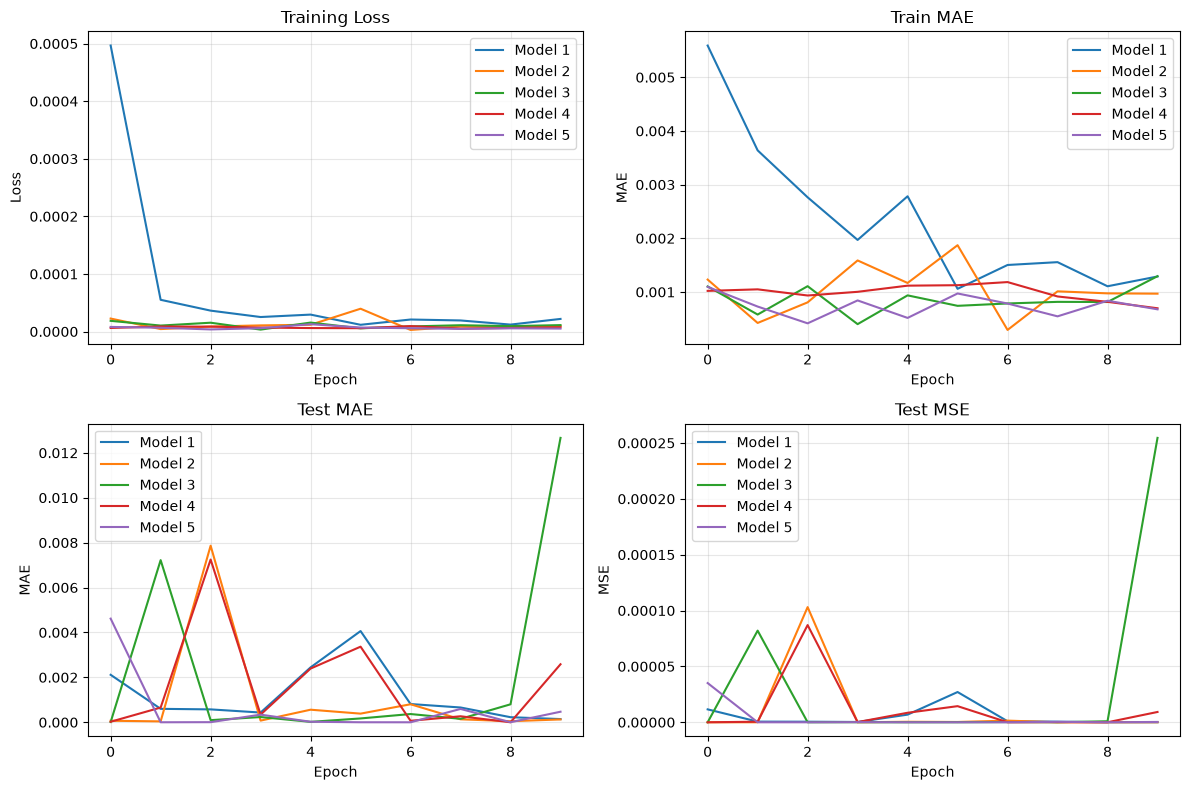

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

metrics = [
    ("Training Loss", "Loss", [p[0].detach().cpu().numpy() for p in models_performance]),
    ("Train MAE", "MAE", [p[1] for p in models_performance]),
    ("Test MAE", "MAE", [p[2] for p in models_performance]),
    ("Test MSE", "MSE", [p[3] for p in models_performance]),
]

for ax, (title, ylabel, model_metrics) in zip(axes.flat, metrics):
    for model_index, values in enumerate(model_metrics, start=1):
        ax.plot(values, label=f"Model {model_index}")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

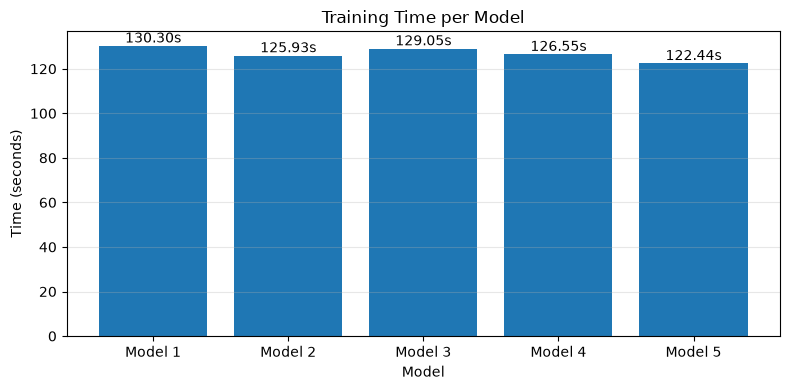

In [11]:
model_names = [f"Model {i + 1}" for i in range(len(models_performance))]
run_times = [p[4] for p in models_performance]

plt.figure(figsize=(8, 4))
plt.bar(model_names, run_times)

plt.title("Training Time per Model")
plt.xlabel("Model")
plt.ylabel("Time (seconds)")
plt.grid(axis="y", alpha=0.3)

for i, run_time in enumerate(run_times):
    plt.text(i, run_time, f"{run_time:.2f}s", ha="center", va="bottom")

plt.tight_layout()
plt.show()

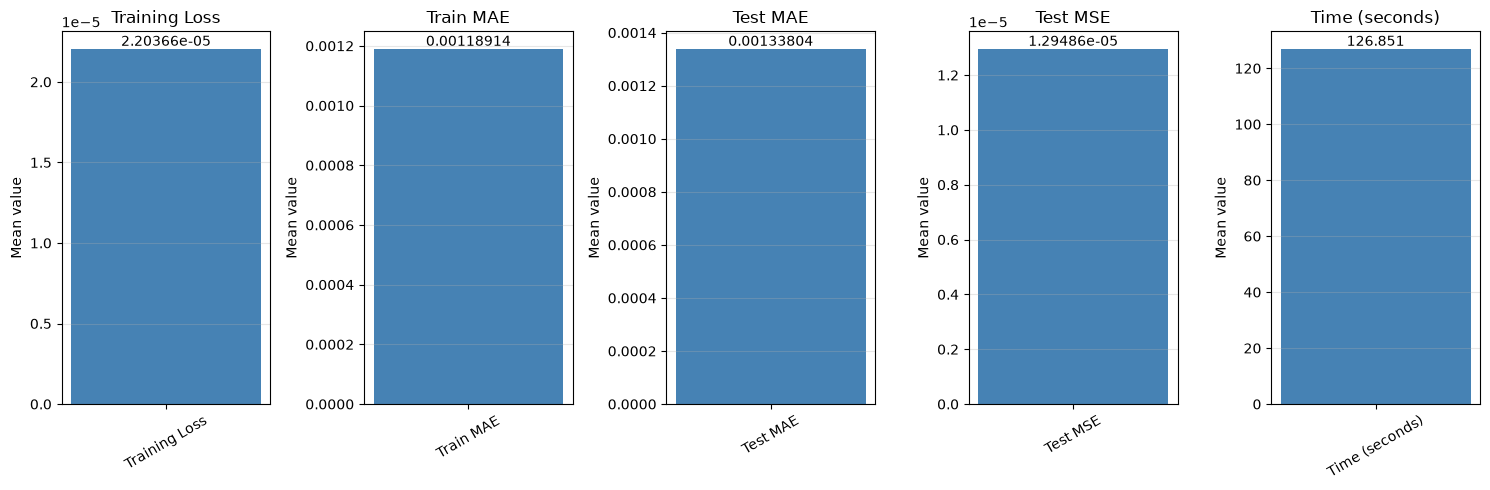

In [12]:
import numpy as np
import matplotlib.pyplot as plt

metric_means = {
    "Training Loss": np.mean([
        p[0].detach().cpu().numpy().mean()
        for p in models_performance
    ]),
    "Train MAE": np.mean([
        np.mean(p[1])
        for p in models_performance
    ]),
    "Test MAE": np.mean([
        np.mean(p[2])
        for p in models_performance
    ]),
    "Test MSE": np.mean([
        np.mean(p[3])
        for p in models_performance
    ]),
    "Time (seconds)": np.mean([
        p[4]
        for p in models_performance
    ])
}

fig, axes = plt.subplots(1, 5, figsize=(15, 5))

for ax, (label, value) in zip(axes, metric_means.items()):
    ax.bar([label], [value], color="steelblue")

    ax.set_title(label)
    ax.set_ylabel("Mean value")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)
    ax.text(
        0,
        value,
        f"{value:.6g}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# Evaluate last model

In [ ]:

import torch
import torch.nn.functional as F

def evaluate_model(model, test_loader, device):
    model.eval()

    total_squared_error = 0.0
    total_absolute_error = 0.0
    total_samples = 0

    with torch.no_grad():
        for X, y in test_loader:
            X = X.to(device)
            y = y.to(device)

            predictions = model(X).squeeze(-1)

            # Convertir de escala normalizada a escala original
            predictions = predictions * 20
            targets = y * 20

            total_squared_error += F.mse_loss(
                predictions, targets, reduction="sum"
            ).item()

            total_absolute_error += F.l1_loss(
                predictions, targets, reduction="sum"
            ).item()

            total_samples += y.size(0)

    mse = total_squared_error / total_samples
    mae = total_absolute_error / total_samples
    rmse = mse ** 0.5

    print(f"MSE:  {mse:.6f}")
    print(f"MAE:  {mae:.6f}")
    print(f"RMSE: {rmse:.6f}")

    return mse, mae, rmse


In [20]:
import os

while True:
    print("\n\n\nCalculator: Enter two number from -10 to 10 to get their sum.")
    print("Type 'exit' to quit the calculator.")
    num1 = input("Enter the first number: ")
    
    if num1 == "exit":
            print("Exiting the calculator.")
            break
        
    num2 = input("Enter the second number: ")
    
    if num2 == "exit":
        print("Exiting the calculator.")
        break
    
    # Check if the inputs are within the valid range
    if not (-10 <= int(num1) <= 10) or not (-10 <= int(num2) <= 10):
        print("Error: Please enter numbers between -10 and 10.")
        continue
    
    # Normalize the inputs
    norm_num1 = int(num1) / 10.0
    norm_num2 = int(num2) / 10.0 
    
    # Create a tensor for the inputs
    input_tensor = torch.tensor([[norm_num1, norm_num2]], dtype=torch.float32)
    
    # Make a prediction using the trained model
    net.eval()
    with torch.no_grad():
        prediction = net(input_tensor).item()
    
    # Denormalize the prediction
    denorm_prediction = prediction * 20.0
    
    # Display the result
    print(f"The predicted sum of {num1} and {num2} is: {round(denorm_prediction)}")




Calculator: Enter two number from -10 to 10 to get their sum.
Type 'exit' to quit the calculator.
The predicted sum of 9 and -5 is: 4



Calculator: Enter two number from -10 to 10 to get their sum.
Type 'exit' to quit the calculator.
Exiting the calculator.
